# 01 - Exploratory Data Analysis
**Structural Damage Classification** - gempa Gorkha 25 April 2015 (Mw 7,8).
Target: `damage_grade` (Grade 1-5), metrik kompetisi **Macro F1**.

Alur notebook ini: baca data -> quick EDA (kolom, duplikasi, missing, outlier, distribusi, imbalance, hubungan fitur-target, lokasi, train vs test) -> kesimpulan untuk preprocessing.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scripts.preprocess import load_data, encode_target, CATEGORICAL_COLS

sns.set_theme(style="whitegrid")
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# **1. Read Data**

In [2]:
train, test, sample = load_data()
metadata = pd.read_csv(ROOT / "data" / "metadata.csv") if (ROOT / "data" / "metadata.csv").exists() else None
print("train :", train.shape)
print("test  :", test.shape, "(tanpa kolom damage_grade)")
print("sample:", sample.shape)
train.head()

train : (533465, 17)
test  : (228629, 16) (tanpa kolom damage_grade)
sample: (228629, 2)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

Ada 533.465 baris train dan 228.629 baris test. Di `metadata.csv` flag material superstruktur ada 11 kolom `has_superstructure_*`, tapi di file yang dipakai sudah digabung jadi **satu kolom `superstructure`** (bangunan diberi material utamanya).

In [4]:
if metadata is not None:
    display(metadata)

,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building ...,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before ...,Number
5,age_building,Age of the building (in years),Number
6,plinth_area_sq_ft,Plinth area of the building (in square feet),Number
7,height_ft_pre_eq,Height of the building before the earthquake (...,Number
8,land_surface_condition,Surface condition of the land in which the bui...,Categorical
9,foundation_type,Type of foundation used in the building,Categorical


# **2. Quick EDA**

### 2.1 Kolom yang tidak dipakai langsung

In [5]:
print("building_id unik di train :", train.building_id.is_unique)
print("building_id unik di test  :", test.building_id.is_unique)
print("irisan building_id train-test:", len(set(train.building_id) & set(test.building_id)))
print("panjang building_id (digit):", train.building_id.astype(str).str.len().value_counts().to_dict())

building_id unik di train : True
building_id unik di test  : True


irisan building_id train-test: 0


panjang building_id (digit): {12: 533465}


`building_id` hanya pengenal unik, jadi **tidak dipakai mentah-mentah** sebagai fitur. Tapi 12 digitnya memuat kode lokasi (2 digit pertama = district), jadi nanti diturunkan jadi `b_vdc`, `b_ward`, `b_seq` di feature engineering. Tidak ada kebocoran id antara train dan test.

### 2.2 Cek duplikasi data

In [6]:
fitur = [c for c in train.columns if c not in ("building_id", "damage_grade")]
print("duplikat building_id                 :", int(train.building_id.duplicated().sum()))
print("duplikat baris (semua kolom)         :", int(train.duplicated().sum()))
print("baris dengan fitur identik (tanpa id):", int(train.duplicated(subset=fitur).sum()))

# apakah bangunan berfitur identik punya label yang sama?
g = train.groupby(fitur)["damage_grade"].nunique()
print(f"kelompok fitur identik: {len(g):,} | yang labelnya bertentangan: {(g > 1).mean() * 100:.1f}%")

duplikat building_id                 : 0


duplikat baris (semua kolom)         : 0


baris dengan fitur identik (tanpa id): 34062


kelompok fitur identik: 499,403 | yang labelnya bertentangan: 2.1%


Tidak ada duplikat `building_id`, jadi tidak ada baris yang perlu di-drop. Ada 34.062 baris yang fiturnya identik dengan baris lain, tapi itu **bangunan berbeda** (id berbeda), bukan data dobel, jadi tetap dipertahankan. Dari kelompok fitur identik, hanya sekitar 2,1% yang labelnya bertentangan, artinya *noise* label dari penilaian surveyor kecil dan tidak jadi pembatas utama skor.

### 2.3 Cek missing value

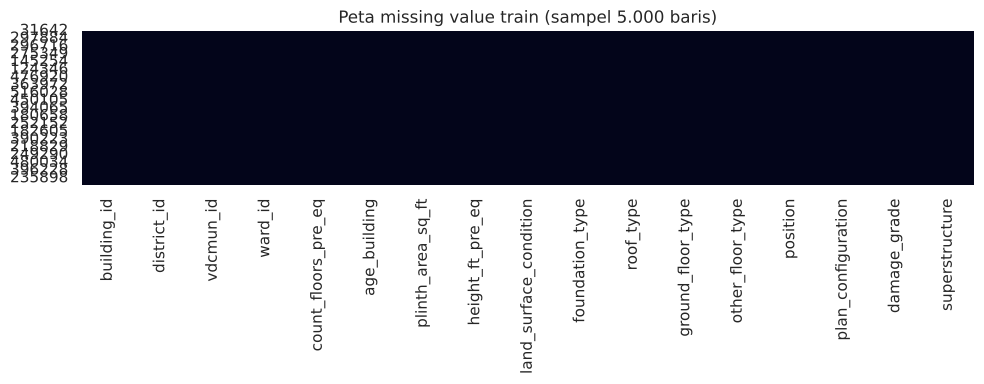

In [7]:
plt.figure(figsize=(10, 4))
sns.heatmap(train.sample(5000, random_state=0).isnull(), cbar=False)
plt.title("Peta missing value train (sampel 5.000 baris)")
plt.tight_layout(); plt.show()

In [8]:
def cek_missing(df):
    return pd.DataFrame({
        "Jumlah": df.isnull().sum(),
        "Persentase": df.isnull().mean() * 100,
    })

print("Train:"); display(cek_missing(train).T)
print("Test:");  display(cek_missing(test).T)

Train:


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
Jumlah,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Persentase,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Test:


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,superstructure
Jumlah,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Persentase,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Tidak ada missing value di train maupun test. Meski begitu, imputer tetap dipasang di pipeline sebagai pengaman (misalnya untuk umur `999` yang nanti diubah jadi NaN).

### 2.4 Cek nilai tidak wajar dan outlier

In [9]:
num_cols = ["count_floors_pre_eq", "age_building", "plinth_area_sq_ft", "height_ft_pre_eq"]
display(train[num_cols].describe().T.round(2))
print("age_building = 999 :", int((train.age_building == 999).sum()), "baris")
print("age_building > 200 :", int((train.age_building > 200).sum()), "baris")
print(train.age_building.value_counts().sort_index().tail(6))

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.09,0.66,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.34,65.00,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.52,226.61,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.05,5.49,6.0,12.0,16.0,18.0,99.0


age_building = 999 : 2198 baris
age_building > 200 : 2198 baris
age_building
190       5
195       2
196       2
199       1
200     178
999    2198
Name: count, dtype: int64


In [10]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lo) | (s > hi)
    return pd.Series({"min": s.min(), "Q1": q1, "median": s.median(), "Q3": q3, "max": s.max(),
                      "batas_bawah": lo, "batas_atas": hi, "n_outlier": int(mask.sum()),
                      "%_outlier": 100 * mask.mean()})

display(pd.DataFrame({c: iqr_outliers(train[c]) for c in num_cols}).T.round(2))

,min,Q1,median,Q3,max,batas_bawah,batas_atas,n_outlier,%_outlier
count_floors_pre_eq,1.0,2.0,2.0,2.0,9.0,2.0,2.0,205799.0,38.58
age_building,0.0,9.0,16.0,27.0,999.0,-18.0,54.0,26735.0,5.01
plinth_area_sq_ft,70.0,280.0,358.0,470.0,5000.0,-5.0,755.0,31219.0,5.85
height_ft_pre_eq,6.0,12.0,16.0,18.0,99.0,3.0,27.0,11724.0,2.20


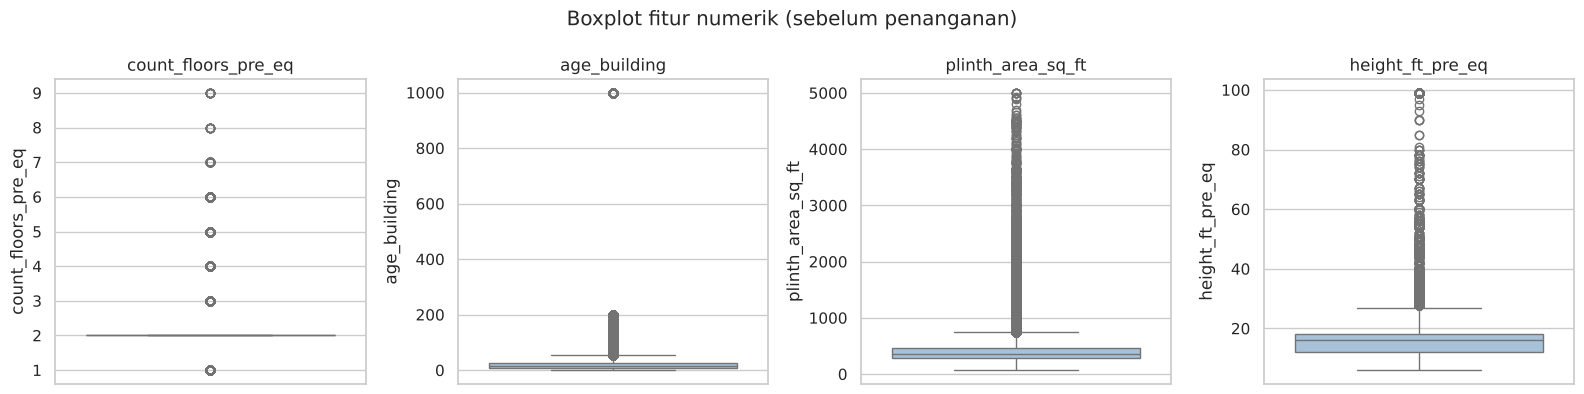

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=train[c], ax=ax, color="#9ec1e0")
    ax.set_title(c)
plt.suptitle("Boxplot fitur numerik (sebelum penanganan)")
plt.tight_layout(); plt.savefig(FIG / "boxplot_numeric.png", dpi=120); plt.show()

**Temuan:** `age_building = 999` bukan umur sungguhan, tapi kode "tidak diketahui" (2.198 baris), jadi ditandai dengan flag `age_unknown` dan umur di-clip ke 200. Outlier IQR pada luas dan tinggi bangunan memang ada tapi masih masuk akal (rumah besar/bertingkat), dan model pohon tidak sensitif terhadap outlier, jadi **tidak dibuang**.

### 2.5 Distribusi fitur numerik

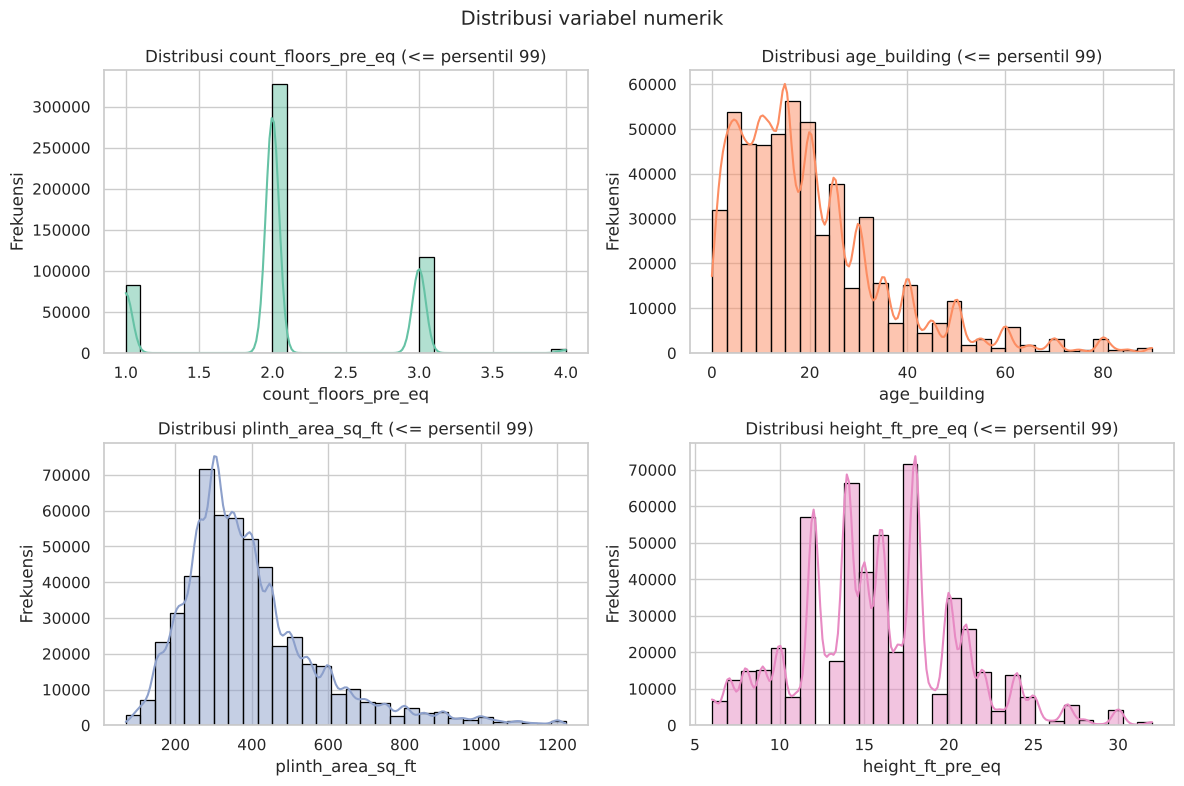

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
palette = sns.color_palette("Set2")
for i, (ax, c) in enumerate(zip(axes.ravel(), num_cols)):
    s = train[c]
    s = s[s <= s.quantile(0.99)]
    sns.histplot(s, kde=True, bins=30, edgecolor="black", color=palette[i], ax=ax)
    ax.set_title(f"Distribusi {c} (<= persentil 99)")
    ax.set_ylabel("Frekuensi")
plt.suptitle("Distribusi variabel numerik", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "numeric_distribution.png", dpi=120); plt.show()

Semua fitur numerik miring ke kanan (kebanyakan bangunan rendah, 1-3 lantai, dan kecil). Untuk model pohon hal ini tidak perlu ditransformasi. Untuk baseline linear nanti dipakai `StandardScaler`.

### 2.6 Distribusi fitur kategorik

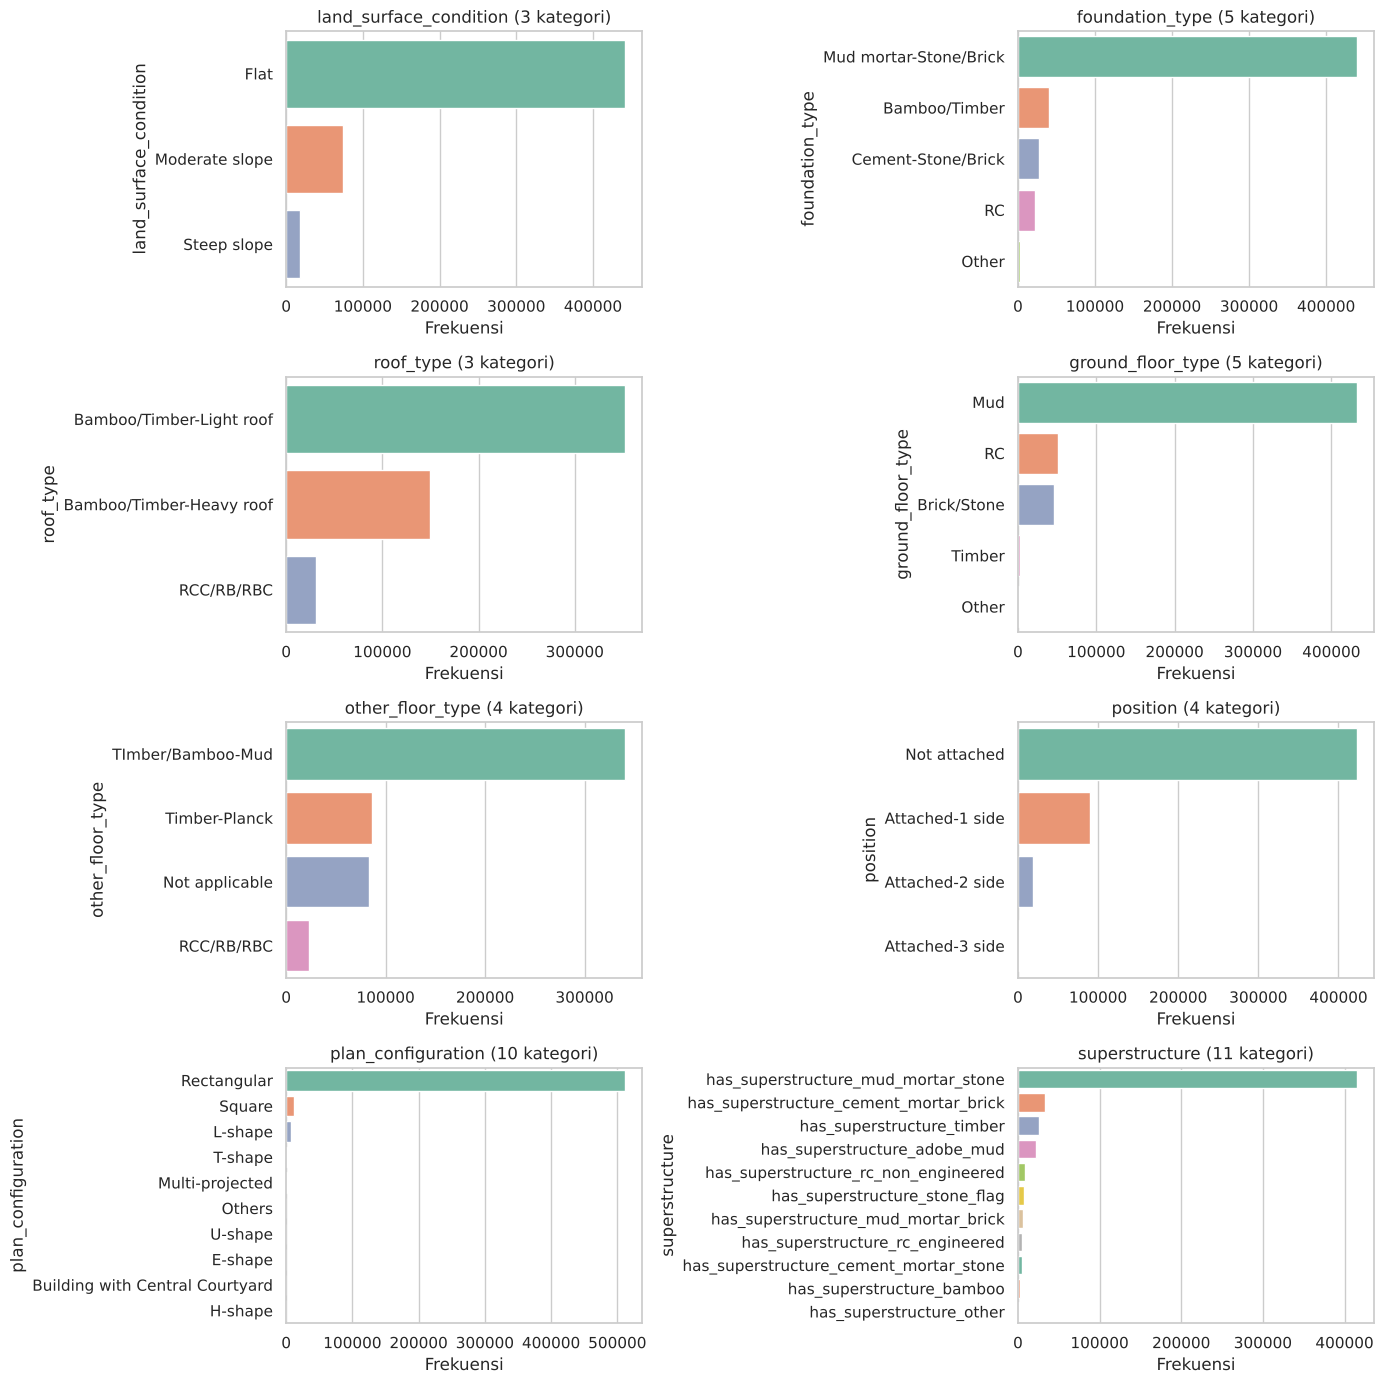

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
for ax, c in zip(axes.ravel(), CATEGORICAL_COLS):
    vc = train[c].value_counts()
    sns.barplot(x=vc.values, y=vc.index, palette="Set2", ax=ax)
    ax.set_title(f"{c} ({len(vc)} kategori)")
    ax.set_xlabel("Frekuensi")
plt.tight_layout(); plt.savefig(FIG / "categorical_distribution.png", dpi=110); plt.show()

Kategori sangat tidak merata: mayoritas bangunan berfondasi *mud mortar - stone/brick*, berlantai dasar lumpur, dan berdenah persegi panjang. Kategori langka (mis. `plan_configuration` selain Rectangular) tetap dipertahankan; encoder diatur `handle_unknown` supaya aman kalau ada kategori baru di test.

### 2.7 Cek imbalance target

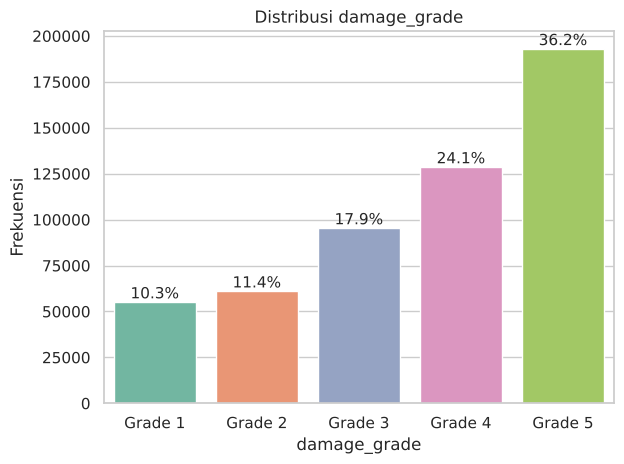

damage_grade
Grade 1    0.103
Grade 2    0.114
Grade 3    0.179
Grade 4    0.241
Grade 5    0.362
Name: proportion, dtype: float64

In [14]:
order = sorted(train.damage_grade.unique())
ax = sns.countplot(x="damage_grade", data=train, order=order, palette="Set2")
total = len(train)
for p in ax.patches:
    ax.annotate(f"{100 * p.get_height() / total:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.title("Distribusi damage_grade"); plt.ylabel("Frekuensi")
plt.tight_layout(); plt.savefig(FIG / "target_distribution.png", dpi=130); plt.show()
train.damage_grade.value_counts(normalize=True).sort_index().round(3)

Kelas **tidak seimbang**: Grade 5 sekitar 36%, Grade 1 sekitar 10%. Karena metrik Macro F1 memberi bobot sama ke tiap kelas, nanti dilakukan **tuning bobot per kelas** pada probabilitas model.

### 2.8 Hubungan fitur dengan target

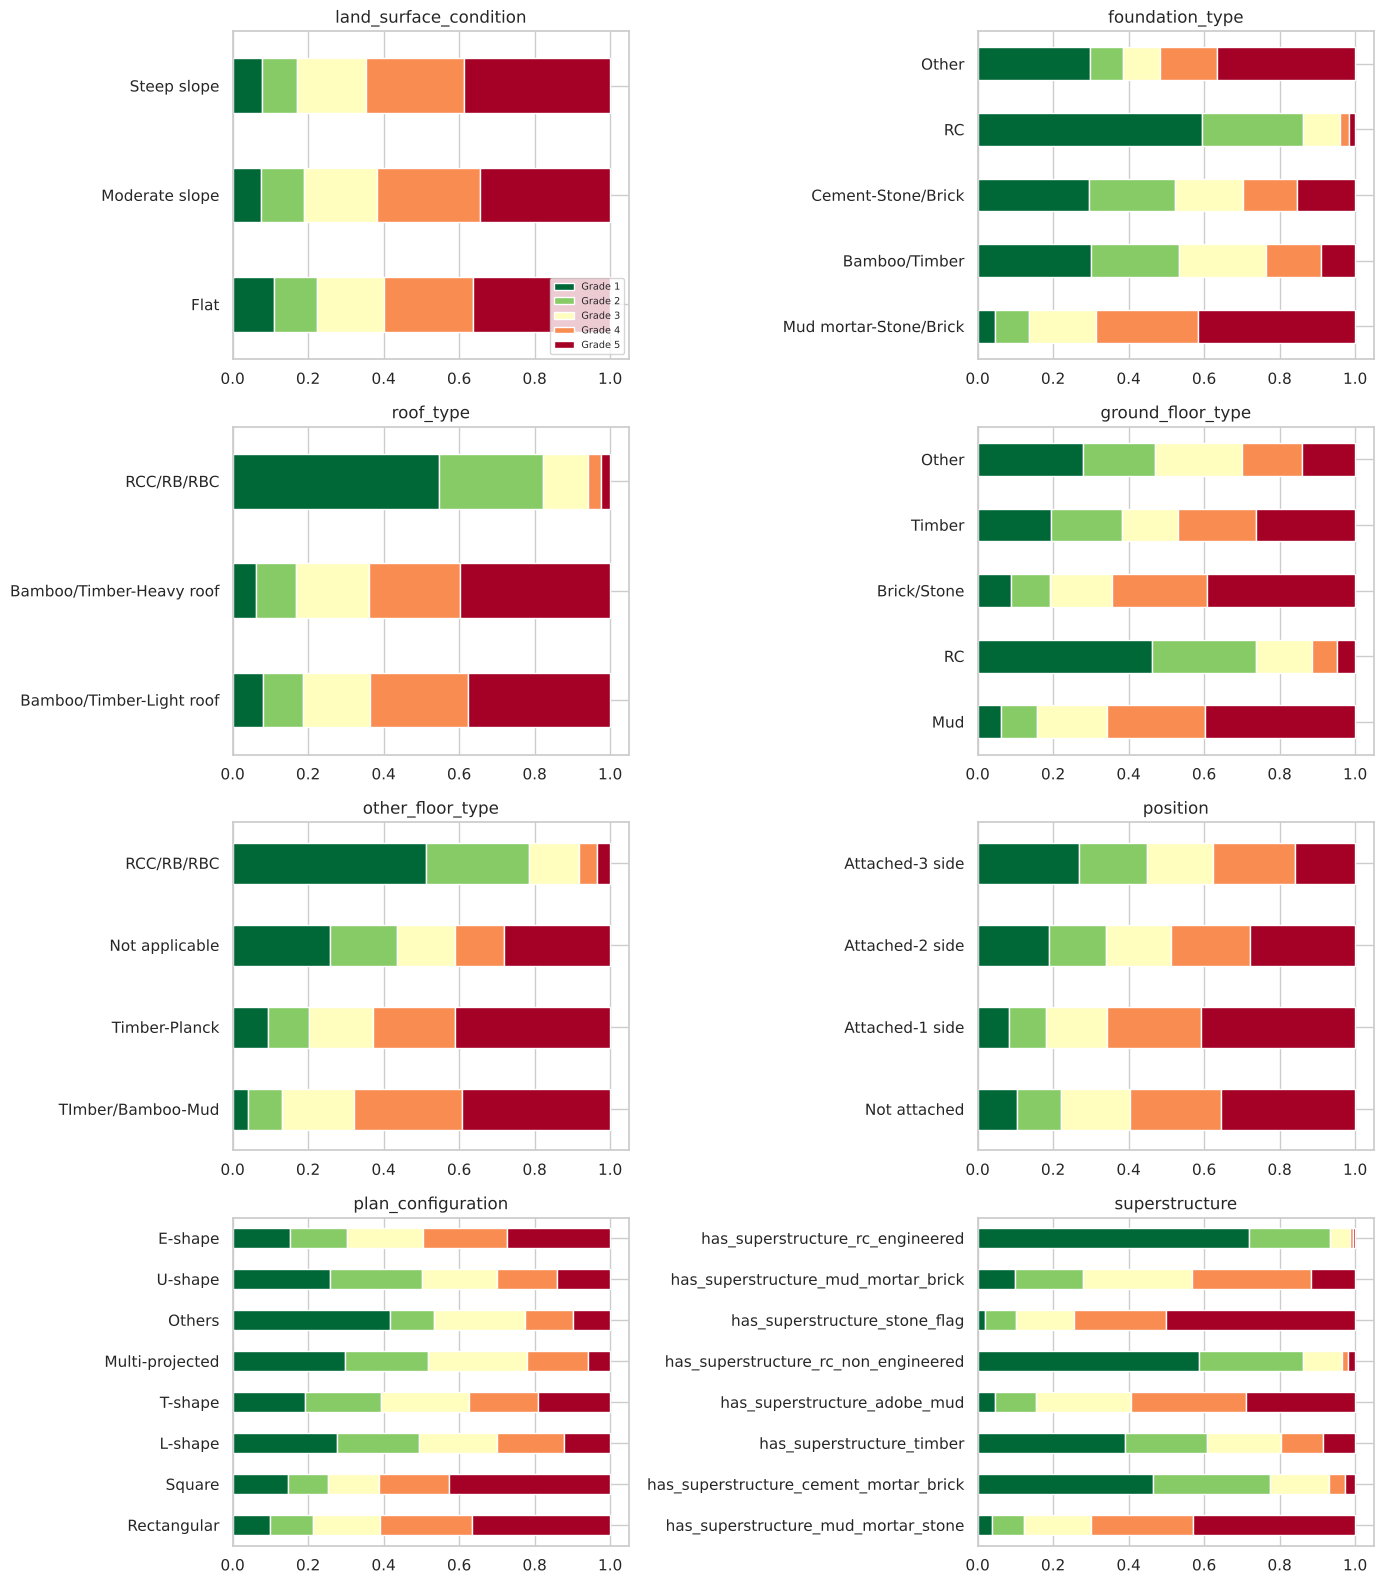

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, c in zip(axes.ravel(), CATEGORICAL_COLS):
    ct = pd.crosstab(train[c], train.damage_grade, normalize="index")
    ct = ct.loc[train[c].value_counts().index[:8]]
    ct.plot.barh(stacked=True, ax=ax, colormap="RdYlGn_r", legend=False)
    ax.set_title(c); ax.set_ylabel("")
axes[0, 0].legend(loc="lower right", fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "categorical_vs_damage.png", dpi=110); plt.show()

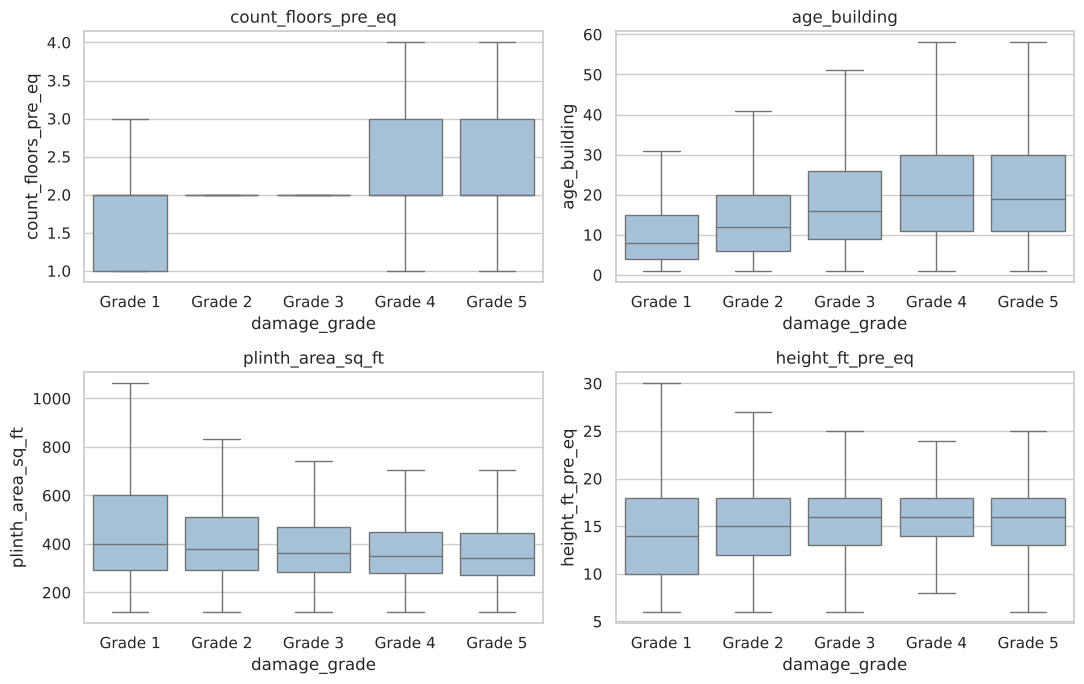

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, c in zip(axes.ravel(), num_cols):
    lo, hi = train[c].quantile([0.01, 0.99])
    sns.boxplot(data=train[train[c].between(lo, hi)], x="damage_grade", y=c, order=order,
                ax=ax, color="#9ec1e0", showfliers=False)
    ax.set_title(c)
plt.tight_layout(); plt.savefig(FIG / "numeric_vs_damage.png", dpi=120); plt.show()

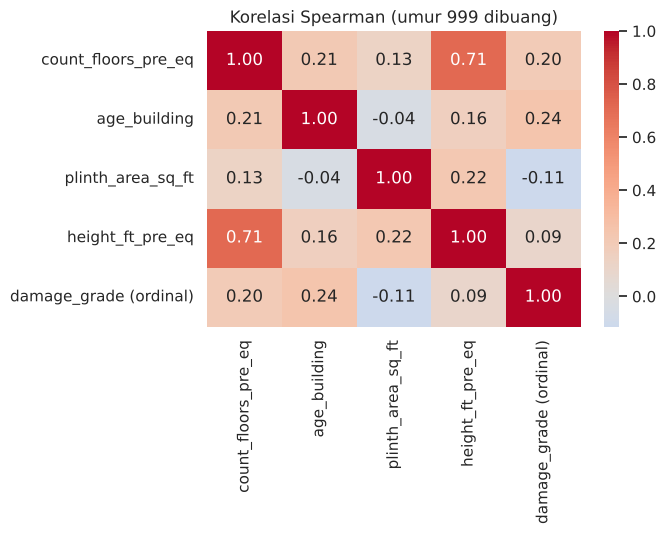

In [17]:
tmp = train[num_cols].copy()
tmp["age_building"] = tmp["age_building"].where(tmp["age_building"] <= 200)
tmp["damage_grade (ordinal)"] = encode_target(train.damage_grade) + 1
plt.figure(figsize=(7, 5.5))
sns.heatmap(tmp.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Spearman (umur 999 dibuang)")
plt.tight_layout(); plt.savefig(FIG / "correlation_heatmap.png", dpi=120); plt.show()

Material dan tipe fondasi/lantai sangat membedakan tingkat kerusakan: struktur lumpur (*mud mortar*) dengan atap berat cenderung Grade 4-5, sedangkan RC/semen cenderung Grade 1-3. Korelasi fitur numerik dengan target lemah-sedang (bangunan lebih tinggi/tua sedikit lebih rusak), jadi hubungannya perlu ditangkap lewat interaksi non-linear.

### 2.9 Lokasi geografis

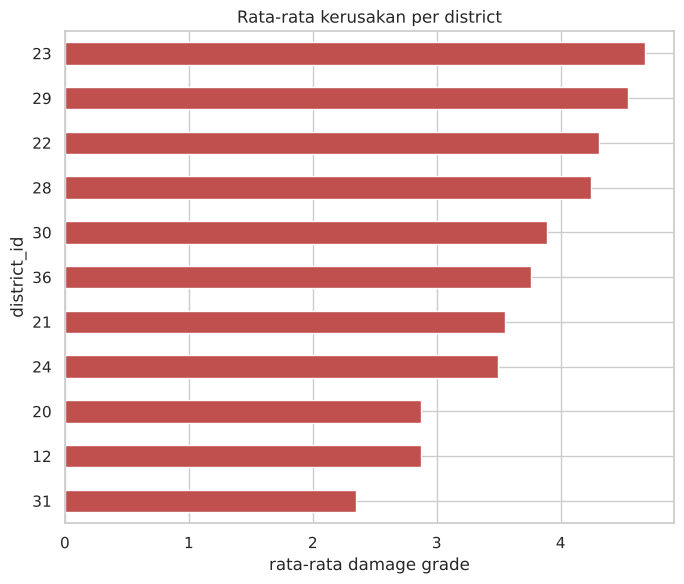

district_id,31,12,20,24,21,36,30,28,22,29,23
mean,2.35,2.87,2.88,3.49,3.55,3.76,3.89,4.24,4.31,4.54,4.68
size,63557.00,27651.00,48133.00,68616.00,41095.00,54751.00,62461.00,53704.00,42465.00,8867.00,62165.00


In [18]:
train["y"] = encode_target(train.damage_grade) + 1
d = train.groupby("district_id").y.agg(["mean", "size"]).sort_values("mean")
ax = d["mean"].plot.barh(figsize=(7, 6), color="#c0504d")
ax.set_xlabel("rata-rata damage grade"); ax.set_title("Rata-rata kerusakan per district")
plt.tight_layout(); plt.savefig(FIG / "district_damage.png", dpi=120); plt.show()
display(d.T.round(2))

In [19]:
b = train.building_id.astype(str).str.zfill(12)
b_vdc = b.str[:4].astype(int)
print("2 digit awal id = district_id :", (b.str[:2].astype(int) == train.district_id).mean())
print("4 digit awal id = vdcmun_id   :", (b_vdc == train.vdcmun_id).mean())
print("jumlah unik  vdcmun_id:", train.vdcmun_id.nunique(), "| b_vdc:", b_vdc.nunique(),
      "| ward_id:", train.ward_id.nunique(), "| 6 digit awal id:", b.str[:6].nunique())
print("std rata-rata damage antar vdcmun_id:", train.groupby("vdcmun_id").y.mean().std().round(3),
      "| antar b_vdc:", train.groupby(b_vdc).y.mean().std().round(3))

2 digit awal id = district_id : 1.0
4 digit awal id = vdcmun_id   : 0.011155371017779985
jumlah unik  vdcmun_id: 110 | b_vdc: 627 | ward_id: 945 | 6 digit awal id: 5666
std rata-rata damage antar vdcmun_id: 0.76 | antar b_vdc: 0.814


Rata-rata kerusakan sangat berbeda antar-district (district yang dekat episentrum jauh lebih parah), jadi lokasi diperkirakan prediktor kuat. Kode dari `building_id` punya lebih banyak kelompok daripada `ward_id`/`vdcmun_id`, jadi memberi lokasi yang lebih halus. Karena kardinalitasnya tinggi, kode lokasi ditangani sebagai kategori native LightGBM, bukan one-hot.

### 2.10 Perbandingan train vs test

In [20]:
cmp = pd.DataFrame({"train_mean": train[num_cols].mean(), "test_mean": test[num_cols].mean()}).round(2)
display(cmp)
for c in ["district_id", "foundation_type", "roof_type"]:
    display(pd.concat([train[c].value_counts(normalize=True), test[c].value_counts(normalize=True)],
                      axis=1, keys=["train", "test"]).head(6).round(3))
print("kategori di test yang tidak ada di train:")
for c in CATEGORICAL_COLS + ["vdcmun_id", "ward_id"]:
    print(f"  {c:25s}", sorted(set(test[c]) - set(train[c])))

,train_mean,test_mean
count_floors_pre_eq,2.09,2.09
age_building,24.34,24.30
plinth_area_sq_ft,406.52,407.02
height_ft_pre_eq,16.05,16.05


,train,test
district_id,,
24,0.129,0.129
31,0.119,0.120
30,0.117,0.117
23,0.117,0.116
36,0.103,0.102
28,0.101,0.103


,train,test
foundation_type,,
Mud mortar-Stone/Brick,0.825,0.825
Bamboo/Timber,0.075,0.076
Cement-Stone/Brick,0.052,0.051
RC,0.042,0.042
Other,0.006,0.006


,train,test
roof_type,,
Bamboo/Timber-Light roof,0.661,0.662
Bamboo/Timber-Heavy roof,0.281,0.280
RCC/RB/RBC,0.058,0.059


kategori di test yang tidak ada di train:
  land_surface_condition    []


  foundation_type           []
  roof_type                 []


  ground_floor_type         []
  other_floor_type          []


  position                  []
  plan_configuration        []


  superstructure            []
  vdcmun_id                 []
  ward_id                   []


Distribusi train dan test hampir sama (split acak), dan tidak ada kategori baru di test, jadi validasi acak berstrata cukup mewakili skor leaderboard.

# **3. Kesimpulan EDA dan keputusan preprocessing**

| Temuan | Keputusan |
|---|---|
| Tidak ada missing value & duplikat id | Tidak ada baris di-drop; imputer tetap dipasang di pipeline sebagai pengaman |
| `age_building = 999` (kode tidak diketahui) | Flag `age_unknown` + umur di-clip 200 |
| Outlier luas/tinggi masih wajar | Dipertahankan (model pohon robust) |
| Fitur numerik miring ke kanan | Turunkan rasio (`area_per_floor`, `height_per_floor`, `slenderness`, `volume_proxy`); scaler hanya untuk baseline linear |
| 8 kolom kategorik, kategori langka | Kategori native LightGBM / OneHot (baseline); `handle_unknown` aman |
| Kode lokasi berkardinalitas tinggi, sangat informatif | `vdcmun_id`, `ward_id`, `b_vdc`, `b_ward` sebagai kategori native; `b_seq` numerik |
| Target imbalance | Stratified split/CV + tuning bobot kelas untuk Macro F1 |
| Train dan test sebaran sama | Validasi acak berstrata (holdout 20% + 5-fold CV) |